In [3]:
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime

In [4]:
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'


In [8]:
data = pd.read_csv('MicrosoftStock.csv')
print(data.head())

    index        date   open   high    low  close    volume  Name
0  390198  2013-02-08  27.35  27.71  27.31  27.55  33318306  MSFT
1  390199  2013-02-11  27.65  27.92  27.50  27.86  32247549  MSFT
2  390200  2013-02-12  27.88  28.00  27.75  27.88  35990829  MSFT
3  390201  2013-02-13  27.93  28.11  27.88  28.03  41715530  MSFT
4  390202  2013-02-14  27.92  28.06  27.87  28.04  32663174  MSFT


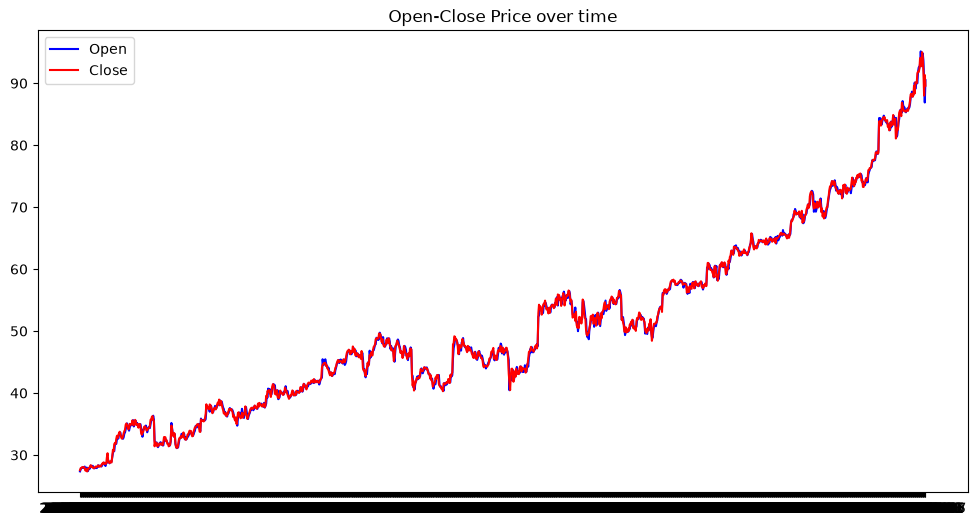

In [11]:
plt.figure(figsize=(12,6))
plt.plot(data['date'], data['open'], label="Open", color="blue")
plt.plot(data['date'], data['close'], label="Close", color="red")
plt.title("Open-Close Price over time")
plt.legend()
# plt.show()

Text(0.5, 1.0, 'Stock volume over time')

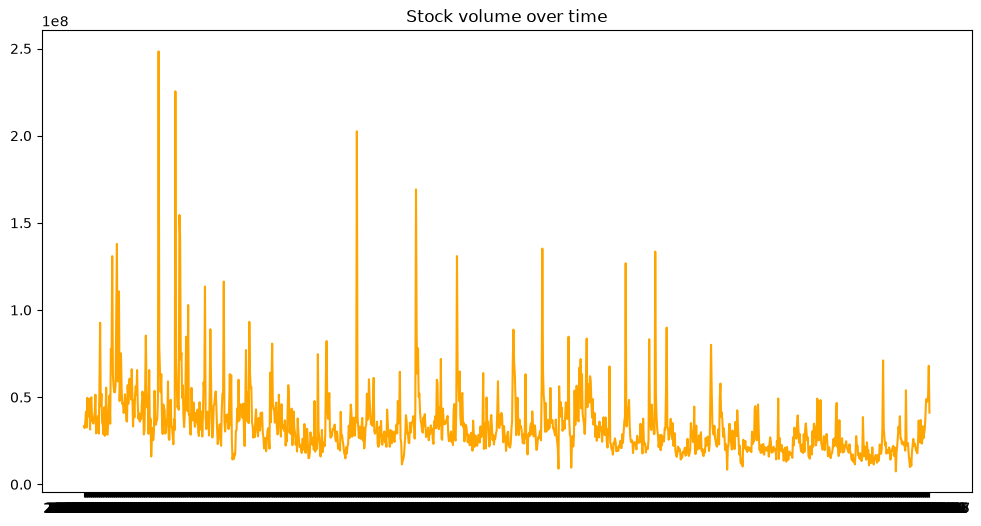

In [14]:
plt.figure(figsize=(12,6))
plt.plot(data['date'], data['volume'], label="Volume", color="orange")
plt.title("Stock volume over time")
# plt.show()

Text(0.5, 1.0, 'Feature Correlation Map')

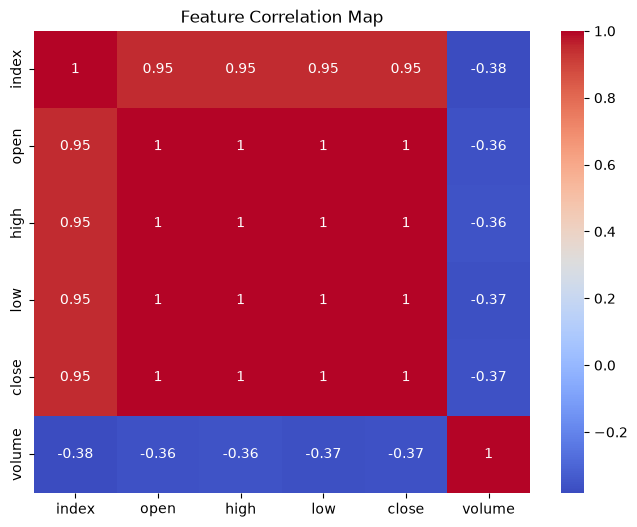

In [12]:
numeric_data = data.select_dtypes(include=["int64", "float64"])

plt.figure(figsize=(8,6))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Map")

In [ ]:
data['date'] = pd.to_datetime(data['date'])
prediction = data.loc[
    (data['date'] > datetime(2013, 1, 1)) &
    (data['date'] < datetime(2018, 1, 1))
]

In [27]:
stock_close = data.filter(['close'])
dataset = stock_close.values # convert to np
training_data_len = int(np.ceil(len(dataset)*0.95))
scaler = StandardScaler()

scaled_data = scaler.fit_transform(dataset)
training_data = scaled_data[:training_data_len]

X_train, y_train = [], []

for i in range(60, len(training_data)):
    X_train.append(training_data[i-60:i,0])
    y_train.append(training_data[i,0])
X_train, y_train = np.array(X_train), np.array(y_train)
X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))


In [28]:
model = keras.models.Sequential()

# First Layer
model.add(keras.layers.LSTM(64, return_sequences=True, input_shape=(X_train.shape[1],1)))

# Second Layer
model.add(keras.layers.LSTM(64, return_sequences=False))

# 3rd Layer (Dense)
model.add(keras.layers.Dense(128, activation="relu"))

# 4th Layer (Dropout)
model.add(keras.layers.Dropout(0.5))

# Final Output Layer
model.add(keras.layers.Dense(1))

model.compile(optimizer='adam', loss='mae', metrics=[keras.metrics.RootMeanSquaredError()])


/Users/shahzaibfareed/Desktop/Desktop - Shahzaib’s MacBook Air/Personal Projects/Python/py-ai-practice/venv/lib/python3.14/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [29]:
training = model.fit(X_train, y_train, epochs=20, batch_size=32)


Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - loss: 0.2264 - root_mean_squared_error: 0.3290
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.1329 - root_mean_squared_error: 0.1837
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.1131 - root_mean_squared_error: 0.1575
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.1100 - root_mean_squared_error: 0.1503
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.1121 - root_mean_squared_error: 0.1482
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1075 - root_mean_squared_error: 0.1493
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1054 - root_mean_squared_error: 0.1419
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.1091 - root_mean_squared_error: 0.1467
Epoch 9/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1012 - root_mean_squared_error: 0.1351
Epoch 10/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.1045 - root_mean_squared_error: 0.1413

In [30]:
# Prep the test data
test_data = scaled_data[training_data_len - 60:]
X_test, y_test = [], dataset[training_data_len:]


for i in range(60, len(test_data)):
    X_test.append(test_data[i-60:i, 0])
    
X_test = np.array(X_test)
X_test = np.reshape(X_test, (X_test.shape[0],X_test.shape[1],1 ))

In [31]:
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step


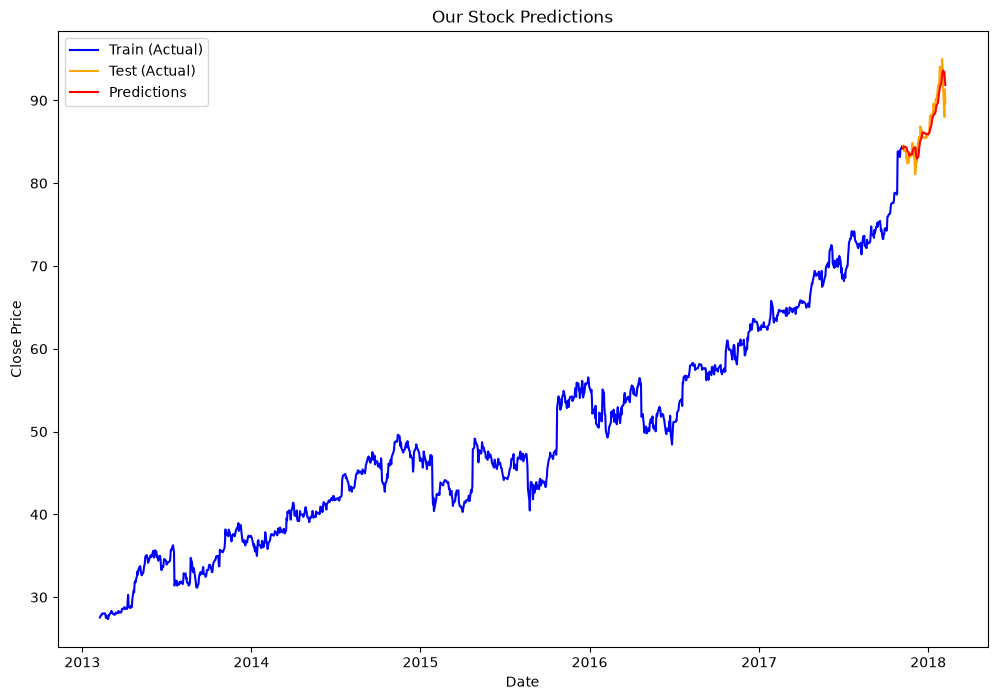

In [32]:
train = data[:training_data_len]
test =  data[training_data_len:]

test = test.copy()

test['Predictions'] = predictions

plt.figure(figsize=(12,8))
plt.plot(train['date'], train['close'], label="Train (Actual)", color='blue')
plt.plot(test['date'], test['close'], label="Test (Actual)", color='orange')
plt.plot(test['date'], test['Predictions'], label="Predictions", color='red')
plt.title("Our Stock Predictions")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.show()